# retail sales
- https://fred.stlouisfed.org/series/RSXFSN
- trend
- seasonality
- regime change

See ch.17,18 of the textbook.
We are not doing train/test here, or evaluating error metrics.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

from sktime.forecasting.naive import NaiveForecaster
from sktime.forecasting.trend import PolynomialTrendForecaster
from statsmodels.tsa.ardl import ARDL
from sktime.utils.plotting import plot_series

In [9]:
# Load directly as a pandas Series
y = pd.read_csv(
    "RSXFSN.csv",
    parse_dates=["observation_date"],
    index_col="observation_date",
    usecols=["observation_date", "RSXFSN"]
)["RSXFSN"]

# Ensure proper frequency and numeric data type for sktime
y = pd.to_numeric(y, errors="coerce").asfreq("MS")

# Verify object
print(type(y))  # <class 'pandas.core.series.Series'>
y.tail()


<class 'pandas.Series'>


observation_date
2026-05-01    664214
2026-06-01    649437
2026-07-01    655940
2026-08-01    655885
2026-09-01    635056
Freq: MS, Name: RSXFSN, dtype: int64

/opt/conda/lib/python3.13/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(


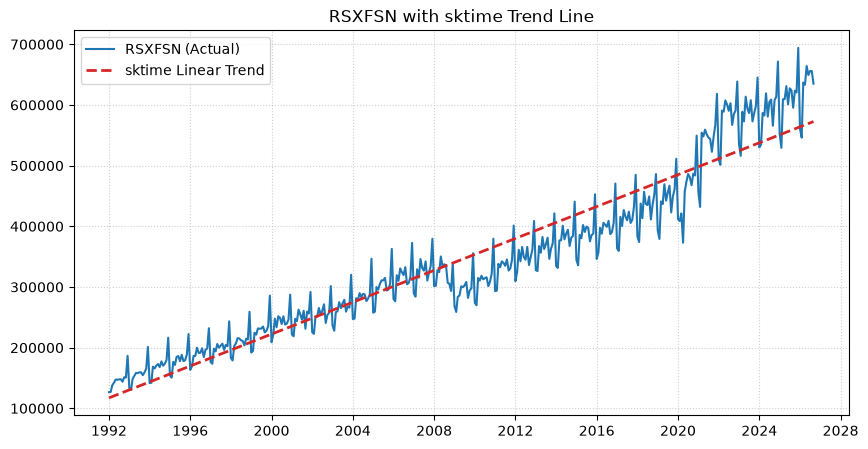

In [10]:
# Fit linear trend (degree=1) using sktime
forecaster = PolynomialTrendForecaster(degree=1)
forecaster.fit(y)

# Generate trend values over the observed time index
y_trend = forecaster.predict(fh=y.index)

# Plot
plt.figure(figsize=(10, 5))
plt.plot(y, label="RSXFSN (Actual)", color="tab:blue")
plt.plot(y_trend, label="sktime Linear Trend", color="tab:red", linestyle="--", linewidth=2)
plt.title("RSXFSN with sktime Trend Line")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [11]:
from statsmodels.tsa.ardl import ARDL

# Ensure y is a pd.Series with Month Start frequency

# Fit ARDL model with autoregressive lags (e.g., lags=1 or lags=[1, 12]) 
# and monthly deterministic seasonal dummies
model = ARDL(
    endog=y,
    lags=1,              # AR(1) short-term dynamics
    seasonal=True,       # Adds 11 indicator variables for monthly seasonality
    period=12,           # Monthly periodicity
    trend="ct"           # Includes an intercept 'c'onstant and linear 't'rend
).fit()

print(model.summary())

                              ARDL Model Results                              
Dep. Variable:                 RSXFSN   No. Observations:                  417
Model:                 Seas. ARDL(1,)   Log Likelihood               -4516.794
Method:               Conditional MLE   S.D. of innovations          12565.852
Date:                Thu, 22 Oct 2026   AIC                           9063.587
Time:                        14:14:03   BIC                           9124.047
Sample:                    02-01-1992   HQIC                          9087.493
                         - 09-01-2026                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const      -7.456e+04   3894.727    -19.143      0.000   -8.22e+04   -6.69e+04
trend         74.6184     20.506      3.639      0.000      34.305     114.932
s(2,12)     7.532e+04   3438.620     21.904      0.0

2026-10-01    642711.735353
2026-11-01    645315.036956
2026-12-01    691261.369108
2027-01-01    603431.814478
2027-02-01    596675.107545
2027-03-01    636916.574030
2027-04-01    627724.498120
2027-05-01    646029.362976
2027-06-01    634390.682950
2027-07-01    633811.267833
2027-08-01    638528.176053
2027-09-01    614459.270894
Freq: MS, dtype: float64


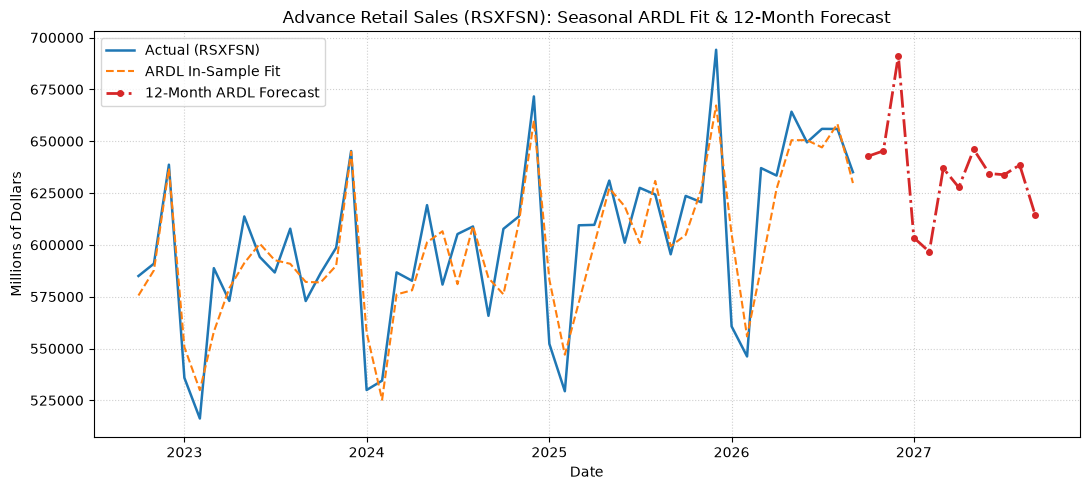

In [6]:
# 2. Extract in-sample fitted values
y_fitted = model.fittedvalues

# 3. Forecast out-of-sample for the next 12 months
n_forecast = 12
y_forecast = model.predict(start=len(y), end=len(y) + n_forecast - 1)
print(y_forecast)

# 4. Plot historical data, fitted values, and out-of-sample forecast
plt.figure(figsize=(11, 5))

# Plot historical actuals (showing last 4 years for visual clarity)
plt.plot(y.index[-48:], y[-48:], label="Actual (RSXFSN)", color="tab:blue", linewidth=1.8)

# Plot in-sample ARDL fit
plt.plot(y_fitted.index[-48:], y_fitted[-48:], label="ARDL In-Sample Fit", color="tab:orange", linestyle="--", linewidth=1.5)

# Plot 12-month ahead forecast
plt.plot(y_forecast.index, y_forecast, label="12-Month ARDL Forecast", color="tab:red", linestyle="-.", linewidth=2, marker="o", markersize=4)

plt.title("Advance Retail Sales (RSXFSN): Seasonal ARDL Fit & 12-Month Forecast")
plt.xlabel("Date")
plt.ylabel("Millions of Dollars")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

Weird stuff happened between 2008 financial crisis and Covid.
So re-do the forecast with an exogenous variable indicating that 
we're into recent history.

In [7]:
# Create a single binary indicator for the post-COVID stimulus regime shift
# 0 prior to 2023, 1 onward
post_covid = (y.index >= "2023-01-01").astype(int)

# Wrap into a DataFrame for the exogenous parameter
exog_data = pd.DataFrame({"post_covid": post_covid}, index=y.index)

# 2. Fit the ARDL model
# order=0 specifies contemporaneous inclusion (no lags of the dummy)
model_post_covid = ARDL(
    endog=y,
    lags=1,
    exog=exog_data,
    order=0,
    seasonal=True,
    period=12,
    trend="ct"
).fit()

print(model_post_covid.summary())

# 1. Define future dates for a 12-month ahead forecast
future_dates = pd.date_range(
    start=y.index[-1] + pd.DateOffset(months=1),
    periods=12,
    freq="MS"
)

# Set post_covid = 1 for out-of-sample periods
exog_future = pd.DataFrame({"post_covid": 1}, index=future_dates)

# Generate forecast using 'exog_oos'
y_forecast = model_post_covid.predict(
    start=len(y),
    end=len(y) + 11,
    exog_oos=exog_future
)

print(y_forecast)

                              ARDL Model Results                              
Dep. Variable:                 RSXFSN   No. Observations:                  417
Model:               Seas. ARDL(1, 0)   Log Likelihood               -4513.255
Method:               Conditional MLE   S.D. of innovations          12459.406
Date:                Thu, 22 Oct 2026   AIC                           9058.509
Time:                        14:11:11   BIC                           9123.000
Sample:                    02-01-1992   HQIC                          9084.009
                         - 09-01-2026                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -6.619e+04   5013.239    -13.203      0.000    -7.6e+04   -5.63e+04
trend           108.3700     24.083      4.500      0.000      61.025     155.715
s(2,12)        7.179e+04   3669.537     

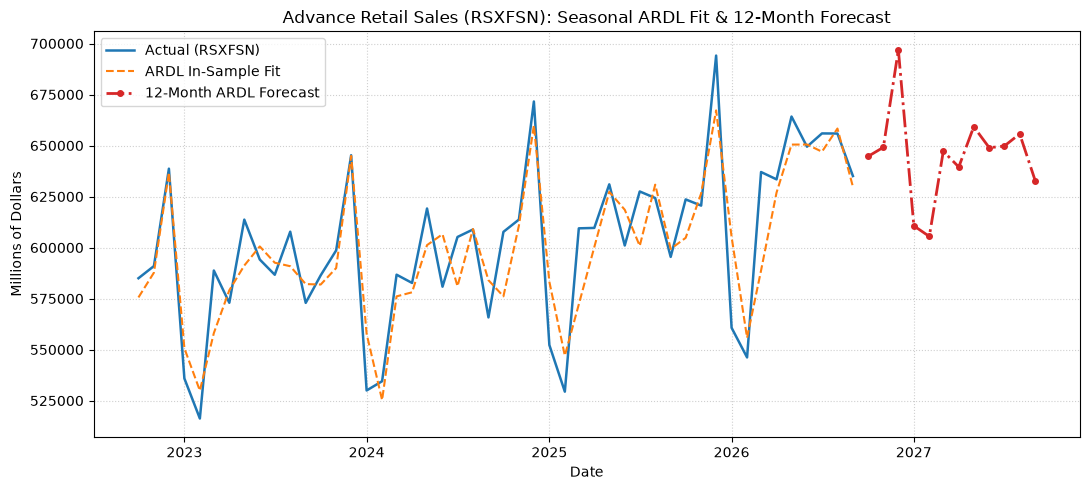

In [8]:
# 4. Plot historical data, fitted values, and out-of-sample forecast
plt.figure(figsize=(11, 5))

# Plot historical actuals (showing last 4 years for visual clarity)
plt.plot(y.index[-48:], y[-48:], label="Actual (RSXFSN)", color="tab:blue", linewidth=1.8)

# Plot in-sample ARDL fit
plt.plot(y_fitted.index[-48:], y_fitted[-48:], label="ARDL In-Sample Fit", color="tab:orange", linestyle="--", linewidth=1.5)

# Plot 12-month ahead forecast
plt.plot(y_forecast.index, y_forecast, label="12-Month ARDL Forecast", color="tab:red", linestyle="-.", linewidth=2, marker="o", markersize=4)

plt.title("Advance Retail Sales (RSXFSN): Seasonal ARDL Fit & 12-Month Forecast")
plt.xlabel("Date")
plt.ylabel("Millions of Dollars")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()